# 🚀 Practice Day 43

**📅 Date:** 2026-10-26  
**📁 Category:** Phase 1 · Pandas 기초 (Round 4/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice core Pandas fundamentals — filtering, sorting, groupby, and aggregation — on a simple single-table dataset
  (기본적인 Pandas 기초 — 필터링, 정렬, groupby, 집계 — 를 단순한 단일 테이블 데이터로 연습하기)
- Find the stationery store's best sellers, which category earns the most, and how revenue varies by day of week
  (문구점의 베스트셀러 상품, 가장 매출이 높은 카테고리, 요일별 매출 변화를 파악하기)

---
# 📂 Dataset

**Dataset Name:** Paper & Pencil Co. — Daily Product Sales / Paper & Pencil Co. — 일별 상품 판매 데이터

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 28 days (March 2024) of daily sales for 8 stationery products across 4 categories (Writing, Paper, Art Supplies, Office Supplies) — 224 rows total (8 products × 28 days), single table. Prices and revenue are in USD. Clean — no missing values or duplicates.
(2024년 3월 28일간 8개 문구 상품(Writing/Paper/Art Supplies/Office Supplies 4개 카테고리)의 일별 판매 데이터입니다(단일 테이블, 224행 = 8상품×28일). 가격과 매출은 USD입니다. 결측치·중복 없이 깨끗합니다.)

## Dataset Preview

In [53]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate 4 weeks of daily sales for 8 stationery products ---
products = {
    'Ballpoint Pen Pack': ('Writing', 3.5),
    'Mechanical Pencil': ('Writing', 2.8),
    'Spiral Notebook': ('Paper', 4.2),
    'Sticky Notes': ('Paper', 2.5),
    'Watercolor Set': ('Art Supplies', 12),
    'Colored Markers': ('Art Supplies', 8.5),
    'Stapler': ('Office Supplies', 6),
    'Desk Organizer': ('Office Supplies', 9.5),
}
base_qty = {
    'Ballpoint Pen Pack': 24, 'Mechanical Pencil': 19, 'Spiral Notebook': 21, 'Sticky Notes': 26,
    'Watercolor Set': 7, 'Colored Markers': 12, 'Stapler': 9, 'Desk Organizer': 6
}

dates = pd.date_range('2024-03-01', periods=28, freq='D')

rows = []
for product, (category, price) in products.items():
    for d in dates:
        noise = rng.normal(1.0, 0.18)
        qty = max(0, int(round(base_qty[product] * noise)))
        revenue = qty * price
        rows.append({'date': d, 'product': product, 'category': category,
                     'quantity_sold': qty, 'revenue': revenue})

df = pd.DataFrame(rows).sort_values(['date', 'product']).reset_index(drop=True)

df.head(10)


,date,product,category,quantity_sold,revenue
0,2024-03-01,Ballpoint Pen Pack,Writing,25,87.5
1,2024-03-01,Colored Markers,Art Supplies,13,110.5
2,2024-03-01,Desk Organizer,Office Supplies,7,66.5
3,2024-03-01,Mechanical Pencil,Writing,20,56.0
4,2024-03-01,Spiral Notebook,Paper,20,84.0
5,2024-03-01,Stapler,Office Supplies,9,54.0
6,2024-03-01,Sticky Notes,Paper,20,50.0
7,2024-03-01,Watercolor Set,Art Supplies,6,72.0
8,2024-03-02,Ballpoint Pen Pack,Writing,20,70.0
9,2024-03-02,Colored Markers,Art Supplies,10,85.0


## Dataset Information

In [54]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 224 entries, 0 to 223
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           224 non-null    datetime64[us]
 1   product        224 non-null    str           
 2   category       224 non-null    str           
 3   quantity_sold  224 non-null    int64         
 4   revenue        224 non-null    float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 8.9 KB

Shape: (224, 5)


,date,product,category,quantity_sold,revenue
count,224,224,224,224.000000,224.000000
unique,NaN,8,4,NaN,NaN
top,NaN,Ballpoint Pen Pack,Writing,NaN,NaN
freq,NaN,28,56,NaN,NaN
mean,2024-03-14 12:00:00,NaN,NaN,15.343750,72.912946
min,2024-03-01 00:00:00,NaN,NaN,4.000000,38.000000
25%,2024-03-07 18:00:00,NaN,NaN,8.000000,56.750000
50%,2024-03-14 12:00:00,NaN,NaN,15.500000,70.000000
75%,2024-03-21 06:00:00,NaN,NaN,22.000000,85.000000
max,2024-03-28 00:00:00,NaN,NaN,32.000000,144.500000


---
# ❓ Business Questions

1. **(Analysis)** Which product sold the most units overall, and which sold the least?
   (전체 기간 기준 가장 많이/적게 팔린 상품은?)
2. **(Analysis)** Which category generated the most total revenue, and which the least?
   (가장 매출이 높은/낮은 카테고리는?)
3. **(Analysis)** How does average daily revenue vary by day of week?
   (요일별 평균 일일 매출은 어떻게 다른가?)
4. **(Visualization)** Compare total units sold across all 8 products.
   (8개 상품의 총 판매량을 비교하면?)
5. **(Visualization)** Show how daily revenue moves across the month.
   (한 달간 일별 매출은 어떻게 변화하는가?)

---
# 🔍 Data Cleaning Check

Things I checked:
- [x] Missing Values — 0
  (결측 없음)
- [x] Duplicate Rows — 0
  (중복 행 없음)
- [x] Wrong Data Types — `date` is datetime, `quantity_sold` is int, `revenue` is float; no fix needed
  (date는 datetime, quantity_sold는 정수, revenue는 실수. 수정 불필요)
- [ ] Rename Columns — not needed
  (불필요)
- [ ] Drop Columns — not needed
  (불필요)


In [55]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
date             0
product          0
category         0
quantity_sold    0
revenue          0
dtype: int64

Duplicate rows: 0

Dtypes
date             datetime64[us]
product                     str
category                    str
quantity_sold             int64
revenue                 float64
dtype: object

Column names
['date', 'product', 'category', 'quantity_sold', 'revenue']

Text columns — unique counts
product     8
category    4
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which product sold the most units overall, and which sold the least? (가장 많이/적게 팔린 상품은?)

**Result:** Sticky Notes sold the most units (**692**). Desk Organizer sold the least (**167**).  
(가장 많이 팔린 상품은 Sticky Notes **692**개, 가장 적게 팔린 상품은 Desk Organizer **167**개)

**Insight:** Sticky Notes (**692**) and Ballpoint Pen Pack (**670**) are close at the top. Desk Organizer is last at **167**.  
(상위는 Sticky Notes **692**와 Ballpoint Pen Pack **670**으로 가깝고, Desk Organizer는 **167**로 마지막)

In [56]:
# Question 1: total quantity sold by product (most / least)
revenue_by_product = df.groupby('product')['quantity_sold'].sum().sort_values(ascending=False)

revenue_by_product

product
Sticky Notes          692
Ballpoint Pen Pack    670
Spiral Notebook       586
Mechanical Pencil     541
Colored Markers       326
Stapler               256
Watercolor Set        199
Desk Organizer        167
Name: quantity_sold, dtype: int64

## Question 2

**Question:** Which category generated the most total revenue, and which the least? (가장 매출이 높은/낮은 카테고리는?)

**Result:** Art Supplies has the highest total revenue (**$5159.0**). Office Supplies has the lowest (**$3122.5**).  
(총매출이 가장 높은 카테고리는 Art Supplies **$5159.0**, 가장 낮은 카테고리는 Office Supplies **$3122.5**)

**Insight:** Art Supplies leads Office Supplies by **$2036.5**. Paper is second (**$4191.2**) and Writing is third (**$3859.8**).  
(Art Supplies가 Office Supplies보다 **$2036.5** 높음. Paper **$4191.2**, Writing **$3859.8**)

In [57]:
# Question 2: total revenue by category (highest / lowest)
df.groupby('category')['revenue'].sum().sort_values(ascending=False)

category
Art Supplies       5159.0
Paper              4191.2
Writing            3859.8
Office Supplies    3122.5
Name: revenue, dtype: float64

## Question 3

**Question:** How does average daily revenue vary by day of week? (요일별 평균 매출 변화는?)

**Result:** Thursday is highest (**$597.175**) and Tuesday is lowest (**$559.550**). The gap is **$37.625**.  
(목요일이 **$597.175**로 가장 높고, 화요일이 **$559.550**으로 가장 낮음. 차이는 **$37.625**)

**Insight:** Monday, Thursday, Friday, and Saturday sit near **$595**. Tuesday drops **$35.475** from Monday, and Sunday drops **$34.825** from Saturday.  
(월·목·금·토는 **$595** 근처. 화요일은 월요일보다 **$35.475** 낮고, 일요일은 토요일보다 **$34.825** 낮음)

In [58]:
# Question 3: average daily revenue by day of week

daily_total = df.groupby('date', as_index=False)['revenue'].sum()
day_rev = (
    daily_total.groupby(daily_total['date'].dt.day_name())['revenue']
    .mean()
    .reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
    .reset_index()
)

day_rev['prev_day_rev'] = day_rev['revenue'].shift(1)
day_rev['change'] = day_rev['revenue'] - day_rev['prev_day_rev']
day_rev['pct_change'] = (day_rev['change'] / day_rev['prev_day_rev'] * 100).round(2)
day_rev


,date,revenue,prev_day_rev,change,pct_change
0,Monday,595.025,NaN,NaN,NaN
1,Tuesday,559.550,595.025,-35.475,-5.96
2,Wednesday,580.025,559.550,20.475,3.66
3,Thursday,597.175,580.025,17.150,2.96
4,Friday,595.725,597.175,-1.450,-0.24
5,Saturday,595.225,595.725,-0.500,-0.08
6,Sunday,560.400,595.225,-34.825,-5.85


---
# 📈 Visualization

**Chart 1:** Bar chart — total units sold by product (막대그래프: 상품별 총 판매량)

*Interpretation:* The bars follow the Q1 order, high to low. Sticky Notes is the longest bar (**692**) and Desk Organizer is the shortest (**167**).  
(막대는 Q1 표와 같이 높은 순. Sticky Notes가 가장 길고(**692**), Desk Organizer가 가장 짧음(**167**))

---

**Chart 2:** Line chart — daily revenue trend (선그래프: 일별 매출 추이)

*Interpretation:* Each point is one date's store total. The line rises and falls through March instead of climbing in one direction.  
(각 점은 하루 매장 매출. 3월 선은 한 방향으로 오르기보다 오르내림)

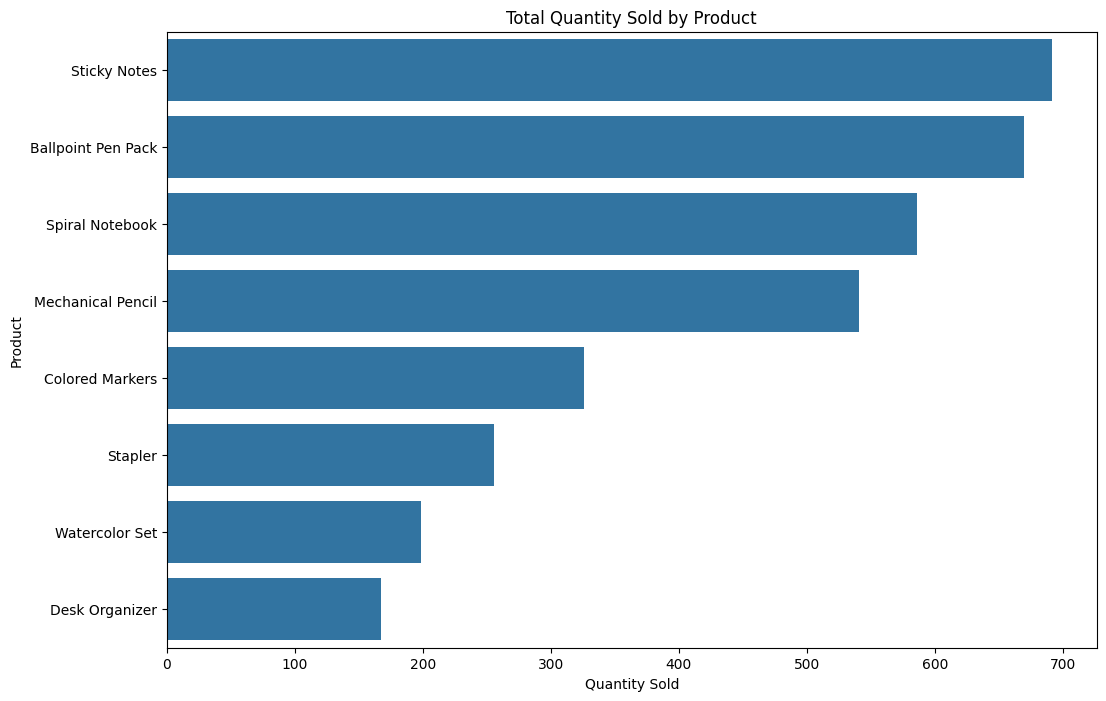

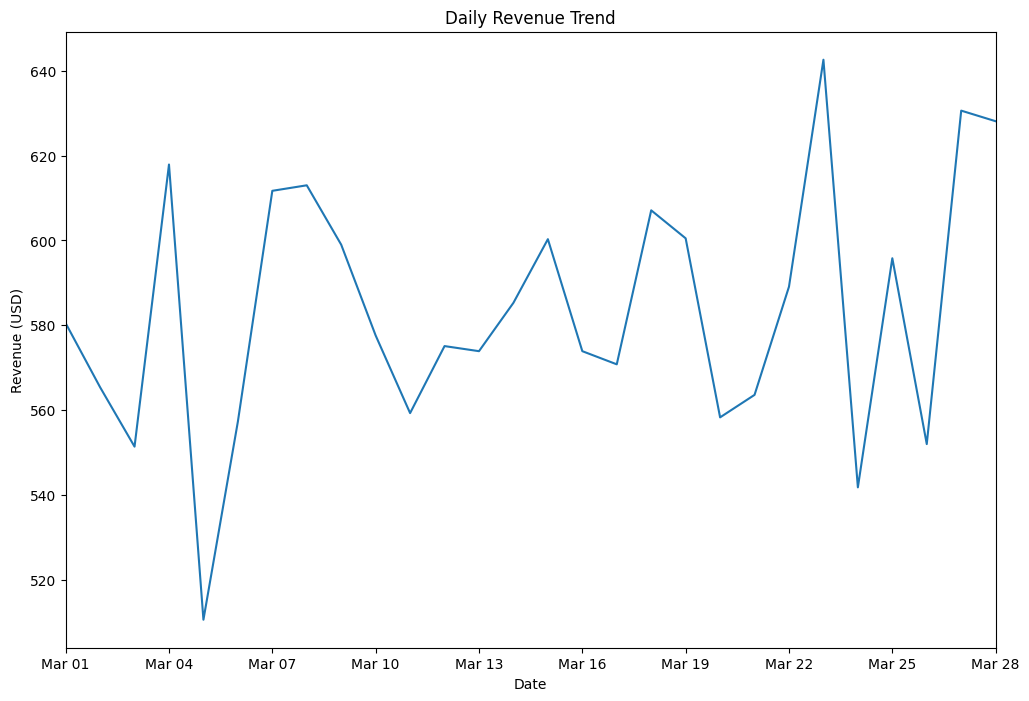

In [60]:
# Visualization
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Chart 1: total quantity sold by product (bar)
fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(x=revenue_by_product.values, y=revenue_by_product.index, ax=ax, estimator=sum, errorbar=None)
ax.set_title('Total Quantity Sold by Product')
ax.set_xlabel('Quantity Sold')
ax.set_ylabel('Product')
plt.show()

# Chart 2: daily revenue trend across the month (line)
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(x='date', y='revenue', data=daily_total, ax=ax, errorbar=None)
ax.set_title('Daily Revenue Trend')
ax.set_xlabel('Date')
ax.set_ylabel('Revenue (USD)')
ax.set_xlim(daily_total['date'].min(), daily_total['date'].max())
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Sticky Notes sold the most units (**692**) and Desk Organizer the least (**167**).  
  (판매량은 Sticky Notes **692**가 가장 많고 Desk Organizer **167**이 가장 적음)
- Art Supplies earned the most revenue (**$5159.0**) and Office Supplies the least (**$3122.5**).  
  (매출은 Art Supplies **$5159.0**이 가장 높고 Office Supplies **$3122.5**가 가장 낮음)
- The unit leader and the revenue leader are not the same.  
  (판매량 1위와 매출 1위는 다름)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Feature Art Supplies first. It is the revenue leader at **$5159.0**.  
   (매출 1위인 Art Supplies **$5159.0**를 앞에 둠)
2. Keep Sticky Notes in stock. It leads units at **692**, even though it is not the revenue leader.  
   (매출 1위는 아니지만 판매량 1위인 Sticky Notes **692**개는 떨어지지 않게 둠)
3. Review Office Supplies. It is the lowest-revenue category at **$3122.5**.  
   (매출이 가장 낮은 Office Supplies **$3122.5**를 점검)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- I added a weekday change column before the average was the store's daily total.  
  (매장 하루 매출로 평균을 구하기 전에 요일 간 변화 열을 넣음)
- Chart 2 first used the weekday table, so it did not show the month day by day.  
  (차트 2가 처음에는 요일 표를 써서 한 달의 일별 추이가 아니었음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `groupby().sum().sort_values(ascending=False)` ranks a total from high to low.  
  (groupby 합계를 내림차순으로 정렬하면 순위가 됨)
- The same sorted series can feed the bar chart, so the bars match the table.  
  (그 정렬된 시리즈로 막대를 그리면 표와 순서가 같음)
- `shift(1)` is the previous row. Subtracting it is the change from that row.  
  (shift(1)은 바로 앞 행이고, 빼면 그 행 대비 변화)  

---
# 🧠 Reflection

**What was difficult?**  
Adding a change column to the weekday averages.  
(요일 평균에 변화 열을 붙이는 것)

**Why?**  
The previous day only makes sense after the rows are in Monday–Sunday order.  
(앞 요일과 비교하려면 월–일 순서가 먼저 필요했음)

**How did I solve it?**  
Used `shift(1)` for the previous value and subtracted it.  
(shift(1)로 앞 값을 두고 빼서 변화를 구함)

**What would I do differently next time?**  
Check that each row is one day of store revenue before comparing weekdays.  
(요일을 비교하기 전에 한 행이 매장 하루 매출인지 확인)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
Product totals, category totals, and the weekday average of daily store revenue are clear.  
(상품 합계, 카테고리 합계, 하루 매출의 요일 평균이 분명함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The groupby totals were familiar. The weekday grain took longer.  
(groupby 합계는 익숙했고, 요일 평균의 단위를 정하는 데 시간이 걸림)

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 44 — NumPy basics (Round 4/5)  
  (NumPy 기초)  